### Overview: Main Data Structures

This notebook uses four main data structures to organize and analyze the ADNI MRI dataset.

| Variable | Data Type | Description |
|---|---|---|
| `metadata` | Dictionary | Stores original MRI metadata loaded from the JSON file, including image IDs, MRI paths, and labels. |
| `class_counts` | Dictionary | Stores the number of AD and NC images in the training and test sets. |
| `image_records` | List of Dictionaries | Stores information for each MRI image, including split, label, filename, image ID, file path, and patient ID. |
| `image_to_subject` | Dictionary | Maps each Image ID to its corresponding Patient ID using the metadata. |

**Data Processing Flow:**

1. Load the original metadata into `metadata`.
2. Count images in each folder using `class_counts`.
3. Collect image information in `image_records`.
4. Extract patient IDs from `metadata` to build `image_to_subject`.
5. Add patient IDs to `image_records` for patient-level overlap analysis.

**Purpose:** These data structures support dataset exploration, patient-level data leakage detection, and preparation for CNN and GFNet training.

# Step 1: Import class

In [10]:
# Import class
import os
import re
import json
from collections import defaultdict, Counter
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from google.colab import drive



# Step 2: Build data path

In [11]:

drive.mount("/content/drive")

# Dataset paths
data_path = "/content/drive/MyDrive/COMP3710/project/dataset/raw"

adni_root = os.path.join(data_path, "ADNI")
adni_path = os.path.join(adni_root, "AD_NC")
json_path = os.path.join(adni_root, "meta_data_with_label.json")

print("Dataset path:", adni_path)
print("Dataset exists:", os.path.isdir(adni_path))
print("Metadata exists:", os.path.isfile(json_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset path: /content/drive/MyDrive/COMP3710/project/dataset/raw/ADNI/AD_NC
Dataset exists: True
Metadata exists: True


# Step 3: Check data

In [12]:
# Load metadata
with open(json_path, "r") as f:
    metadata = json.load(f)

print("Metadata type:", type(metadata))
print("Metadata records:", len(metadata))
print("=" * 50)
# ================================================

# Check folders
for split in ["train", "test"]:
    for label in ["AD", "NC"]:

        folder = os.path.join(adni_path, split, label)

        print(f"{split}/{label}:", "Found" if os.path.isdir(folder) else "Missing")
print("=" * 50)
# ================================================

# Inspect one metadata entry
first_key = next(iter(metadata))

print("\nExample metadata ID:", first_key)
print("Example metadata:", metadata[first_key])
print("=" * 50)

Metadata type: <class 'dict'>
Metadata records: 2189
train/AD: Found
train/NC: Found
test/AD: Found
test/NC: Found

Example metadata ID: 932015
Example metadata: {'c1': 'ADNI_T1_3T_SPM_SEGS_BIN/c1ADNI_068_S_0473_MR_Accelerated_Sagittal_MPRAGE__br_raw_20171116173455030_44_S632432_I932015.nii.gz', 'c2': 'ADNI_T1_3T_SPM_SEGS_BIN/c2ADNI_068_S_0473_MR_Accelerated_Sagittal_MPRAGE__br_raw_20171116173455030_44_S632432_I932015.nii.gz', 'c3': 'ADNI_T1_3T_SPM_SEGS_BIN/c3ADNI_068_S_0473_MR_Accelerated_Sagittal_MPRAGE__br_raw_20171116173455030_44_S632432_I932015.nii.gz', 'c4': 'ADNI_T1_3T_SPM_SEGS_BIN/c4ADNI_068_S_0473_MR_Accelerated_Sagittal_MPRAGE__br_raw_20171116173455030_44_S632432_I932015.nii.gz', 'c5': 'ADNI_T1_3T_SPM_SEGS_BIN/c5ADNI_068_S_0473_MR_Accelerated_Sagittal_MPRAGE__br_raw_20171116173455030_44_S632432_I932015.nii.gz', 'masked': 'ADNI_T1_3T_MASKED_N4/N4_masked_ADNI_068_S_0473_MR_Accelerated_Sagittal_MPRAGE__br_raw_20171116173455030_44_S632432_I932015.nii.gz', 'raw': 'ADNI_T1_3T/ADNI_

# Step 4: Image Counting and Class Distribution Analysis

Class distribution:
train/AD : 10400
train/NC : 11121
test/AD : 4460
test/NC : 4540

Total images: 30521


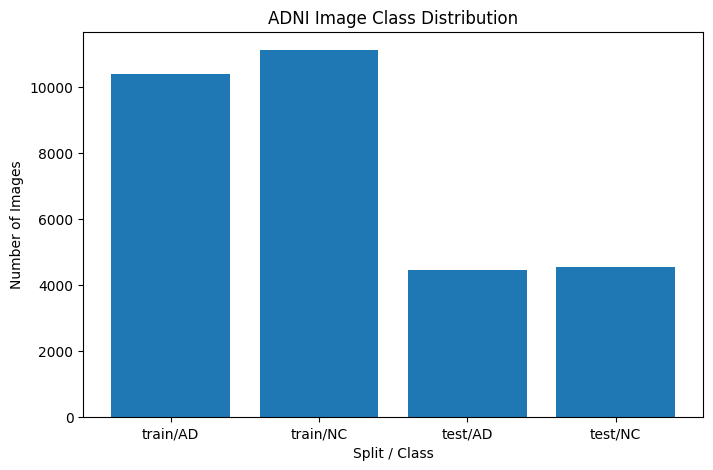

In [13]:
image_extensions = (".jpg", ".jpeg", ".png")

image_records = []
class_counts = {}

for split in ["train", "test"]:
    for label in ["AD", "NC"]:

        # Create folder path
        folder = os.path.join(adni_path, split, label)

        # Get image filenames and sort
        files = []
        for f in os.listdir(folder):
            if f.lower().endswith(image_extensions):
                files.append(f)
        files = sorted(files)

        # Load data
        class_counts[f"{split}/{label}"] = len(files)

        for filename in files:

            # Remove the file extension
            name = os.path.splitext(filename)[0]

            # Extract the image ID
            image_id = name.split("_")[0]

            # Get the full image path
            image_path = os.path.join(folder, filename)

            # Store image information
            record = {
                "split": split,
                "label": label,
                "filename": filename,
                "image_id": image_id,
                "path": image_path
            }

            image_records.append(record)

# Print
print("Class distribution:")
for name, count in class_counts.items():
    print(name, ":", count)

print("\nTotal images:", len(image_records))

plt.figure(figsize=(8, 5))
plt.bar(class_counts.keys(), class_counts.values())
plt.xlabel("Split / Class")
plt.ylabel("Number of Images")
plt.title("ADNI Image Class Distribution")
plt.show()

# Step 5: MRI Image Inspection and Visualization


AD image
Size: (256, 240)
Mode: L
Pixel min: 0
Pixel max: 255
Pixel mean: 29.684342447916666

NC image
Size: (256, 240)
Mode: L
Pixel min: 0
Pixel max: 255
Pixel mean: 30.721370442708334


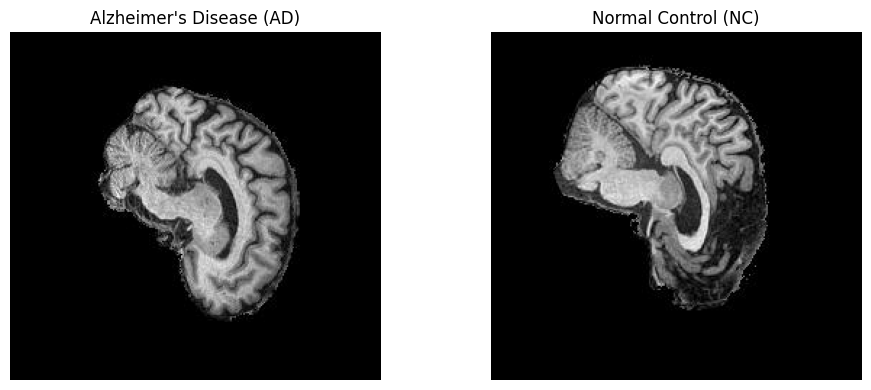

In [14]:
# Select one AD and one NC image
ad_record = next(
    r for r in image_records if r["label"] == "AD"
)

nc_record = next(
    r for r in image_records if r["label"] == "NC"
)

ad_image = Image.open(ad_record["path"])
nc_image = Image.open(nc_record["path"])

for name, image in [("AD", ad_image), ("NC", nc_image)]:
    array = np.array(image)

    print(f"\n{name} image")
    print("Size:", image.size)
    print("Mode:", image.mode)
    print("Pixel min:", array.min())
    print("Pixel max:", array.max())
    print("Pixel mean:", array.mean())
    print("=" * 50)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(ad_image, cmap="gray")
plt.title("Alzheimer's Disease (AD)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(nc_image, cmap="gray")
plt.title("Normal Control (NC)")
plt.axis("off")

plt.tight_layout()
plt.show()



# Step 6: Patient ID Extraction and Image Mapping

In [15]:
# Build image ID -> patient ID mapping
image_to_subject = {}

for image_id, info in metadata.items():

    raw_path = info.get("raw", "")

    match = re.search(r"\d{3}_S_\d{4}", raw_path)

    if match:

      # Extract the patient ID
      patient_id = match.group()

      # Convert image ID to string
      image_id = str(image_id)

      # Store image ID -> patient ID mapping
      image_to_subject[image_id] = patient_id

print("Mapped metadata records:", len(image_to_subject))
print("=" * 50)

# Attach patient ID to each image
missing_images = []

for record in image_records:

    patient_id = image_to_subject.get(record["image_id"])

    record["patient_id"] = patient_id

    if patient_id is None:
        missing_images.append(record["filename"])

print("Total images:", len(image_records))
print("Images without patient ID:", len(missing_images))
print("Examples:", missing_images[:5])

Mapped metadata records: 2189
Total images: 30521
Images without patient ID: 0
Examples: []


# Step 7: Patient-Level Overlap and Data Leakage Detection

In [16]:
train_subjects = set()
test_subjects = set()

subject_labels = defaultdict(set)
unmapped_count = 0

for record in image_records:

    patient_id = record["patient_id"]

    if patient_id is None:
        unmapped_count += 1
        continue

    subject_labels[patient_id].add(record["label"])

    if record["split"] == "train":
        train_subjects.add(patient_id)
    else:
        test_subjects.add(patient_id)

# Patient overlap
overlap = train_subjects & test_subjects

# Check for conflicting patient labels
conflicting_subjects = {}

for patient, labels in subject_labels.items():

    if len(labels) > 1:
        conflicting_subjects[patient] = labels

print("Train unique patients:", len(train_subjects))
print("Test unique patients:", len(test_subjects))
print("Total unique patients:", len(subject_labels))
print("=" * 50)

print("\nOverlapping patients:", len(overlap))
print("Conflicting patient labels:", len(conflicting_subjects))
print("Unmapped images:", unmapped_count)
print("=" * 50)

print("\nOverlap examples:", sorted(overlap)[:10])
print("=" * 50)

if overlap:
    print("\nWARNING: Patient-level data leakage detected.")
else:
    print("\nPASS: No patient overlap detected.")

if conflicting_subjects:
    print("WARNING: Conflicting labels detected.")
else:
    print("PASS: No conflicting patient labels detected.")

Train unique patients: 565
Test unique patients: 331
Total unique patients: 680

Overlapping patients: 216
Conflicting patient labels: 0
Unmapped images: 0

Overlap examples: ['002_S_0413', '002_S_1261', '002_S_4213', '002_S_6007', '002_S_6030', '002_S_6053', '003_S_4373', '003_S_4441', '003_S_5165', '003_S_5187']

PASS: No conflicting patient labels detected.


#Step 8: Data Exploration Summary

In [17]:
print("=" * 50)
print("ADNI DATA EXPLORATION SUMMARY")
print("=" * 50)

print("\n1. Dataset")
print("Total images:", len(image_records))
print("Metadata records:", len(metadata))

print("\n2. Class Distribution")
for name, count in class_counts.items():
    print(f"{name}: {count}")

print("\n3. Image Properties")
print("Example AD size:", ad_image.size)
print("Example NC size:", nc_image.size)
print("Example AD mode:", ad_image.mode)
print("Example NC mode:", nc_image.mode)

print("\n4. Patient-Level Audit")
print("Unique patients:", len(subject_labels))
print("Train patients:", len(train_subjects))
print("Test patients:", len(test_subjects))
print("Overlapping patients:", len(overlap))
print("Conflicting labels:", len(conflicting_subjects))
print("Unmapped images:", unmapped_count)

print("\n5. Final Status")

if len(overlap) == 0 and len(conflicting_subjects) == 0 and unmapped_count == 0:
    print("Patient-level audit passed.")
else:
    print("Patient-level audit requires further action.")

print("\nNext step: Create leakage-free train/validation/test splits.")

ADNI DATA EXPLORATION SUMMARY

1. Dataset
Total images: 30521
Metadata records: 2189

2. Class Distribution
train/AD: 10400
train/NC: 11121
test/AD: 4460
test/NC: 4540

3. Image Properties
Example AD size: (256, 240)
Example NC size: (256, 240)
Example AD mode: L
Example NC mode: L

4. Patient-Level Audit
Unique patients: 680
Train patients: 565
Test patients: 331
Overlapping patients: 216
Conflicting labels: 0
Unmapped images: 0

5. Final Status
Patient-level audit requires further action.

Next step: Create leakage-free train/validation/test splits.


#Step 9: Save and Verify Image Records

In [18]:

# Convert image records to DataFrame
df = pd.DataFrame(image_records)

# Save image records
output_path = "/content/drive/MyDrive/COMP3710/project/dataset/processed/image_records.csv"

df.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("Total records:", len(df))
print("=" * 50)

# Verify saved CSV
saved_df = pd.read_csv(
    output_path,
    dtype={"image_id": str, "patient_id": str}
)

print("Saved records:", len(saved_df))
print("Missing patient IDs:", saved_df["patient_id"].isna().sum())
print(saved_df.head())

Saved to: /content/drive/MyDrive/COMP3710/project/dataset/processed/image_records.csv
Total records: 30521
Saved records: 30521
Missing patient IDs: 0
   split label        filename image_id  \
0  train    AD  218391_78.jpeg   218391   
1  train    AD  218391_79.jpeg   218391   
2  train    AD  218391_80.jpeg   218391   
3  train    AD  218391_81.jpeg   218391   
4  train    AD  218391_82.jpeg   218391   

                                                path  patient_id  
0  /content/drive/MyDrive/COMP3710/project/datase...  037_S_4001  
1  /content/drive/MyDrive/COMP3710/project/datase...  037_S_4001  
2  /content/drive/MyDrive/COMP3710/project/datase...  037_S_4001  
3  /content/drive/MyDrive/COMP3710/project/datase...  037_S_4001  
4  /content/drive/MyDrive/COMP3710/project/datase...  037_S_4001  
